## Part B: Dataset Understanding and Preparation 

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import SGDRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [42]:
df = pd.read_excel(r"C:\Users\tanaa\Downloads\house price.xlsx")
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [44]:
df.describe()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03
mean,102100.500000,1667.357381,3.696667,2.827381,5.611429,23.829524,18.186167,3366.329048,0.642381,0.096190,7.955714,2.364189e+07
std,1212.579894,630.336132,1.574199,1.153585,2.140880,13.945663,8.674549,1658.230565,0.479356,0.294887,7.316766,1.239279e+07
min,100001.000000,450.000000,1.000000,1.000000,1.000000,1.000000,1.000000,800.000000,0.000000,0.000000,0.000000,8.000000e+05
25%,101050.750000,1226.750000,3.000000,2.000000,4.000000,13.000000,11.800000,2122.500000,0.000000,0.000000,2.000000,1.425969e+07
50%,102100.500000,1660.000000,4.000000,3.000000,5.700000,21.000000,17.800000,3188.000000,1.000000,0.000000,6.000000,2.214500e+07
75%,103150.250000,2084.250000,5.000000,4.000000,7.300000,32.000000,24.200000,4364.250000,1.000000,0.000000,12.000000,3.096090e+07
max,104200.000000,4202.000000,7.000000,6.000000,10.000000,80.000000,47.600000,12938.000000,1.000000,1.000000,50.000000,7.611172e+07


In [45]:
df.isna().sum()

house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64

In [46]:
print("Missing values:")
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Missing values:
house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64
Duplicate rows: 0


In [47]:
# house_price_inr is the target. house_id is only an identifier.
X = df.drop(["house_id", "house_price_inr"], axis=1)
y = df["house_price_inr"]

print("Independent variables:", X.columns.tolist())
print("Dependent variable: house_price_inr")

Independent variables: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']
Dependent variable: house_price_inr


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 3360
Testing rows: 840


## Part C: Simple Linear Regression

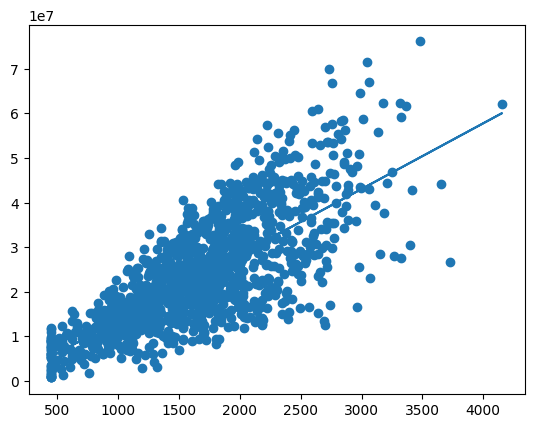

In [49]:
X_simple = df[["area_sqft"]]
y = df["house_price_inr"]
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.3, random_state=42
)
model_simple = LinearRegression()
model_simple.fit(X_train_s, y_train_s)
y_pred_simple = model_simple.predict(X_test_s)


plt.scatter(X_test_s, y_test_s)

plt.plot(X_test_s, y_pred_simple)

plt.show()

In [50]:
mae_simple = mean_absolute_error(y_test_s, y_pred_simple)
mse_simple = mean_squared_error(y_test_s, y_pred_simple)
rmse_simple = np.sqrt(mse_simple)
r2_simple = r2_score(y_test_s, y_pred_simple)
n = len(y_test_s)
p = 1
adjusted_r2_simple = 1 - (1-r2_simple)*(n-1)/(n-p-1)

print("MAE =", mae_simple)
print("MSE =", mse_simple)
print("RMSE =", rmse_simple)
print("R2 =", r2_simple)
print("Adjusted R2 =", adjusted_r2_simple)

MAE = 6341919.212821871
MSE = 67312934455128.94
RMSE = 8204446.017564436
R2 = 0.5679404212239498
Adjusted R2 = 0.5675969716382773


## Part E: Multiple Linear Regression 

In [51]:
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)
y_pred_multi = model_multi.predict(X_test)

mae_multi = mean_absolute_error(y_test, y_pred_multi)
mse_multi = mean_squared_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = r2_score(y_test, y_pred_multi)
n = len(y_test)
p = X_test.shape[1]
adjusted_r2_multi = 1 - (1-r2_multi)*(n-1)/(n-p-1)

print("MAE =", mae_multi)
print("MSE =", mse_multi)
print("RMSE =", rmse_multi)
print("R2 =", r2_multi)
print("Adjusted R2 =", adjusted_r2_multi)

MAE = 2604991.4061556906
MSE = 12592918884127.623
RMSE = 3548650.29048054
R2 = 0.9177606877509897
Adjusted R2 = 0.9167686574464178


In [52]:
coefficients = pd.DataFrame({"Feature": X.columns, "Coefficient": model_multi.coef_})
print(coefficients)
print("Intercept:", model_multi.intercept_)

                Feature   Coefficient
0             area_sqft  1.379594e+04
1              bedrooms  1.976431e+05
2             bathrooms  1.859445e+05
3        location_score  3.073174e+06
4             age_years -6.560924e+04
5      distance_city_km -9.896516e+04
6         lot_size_sqft  1.035058e+02
7            has_garage  9.392436e+04
8              has_pool  4.552902e+05
9  renovation_years_ago -2.143591e+04
Intercept: -14766762.74567468


## Part F: Polynomial Regression

In [53]:
# Polynomial Regression

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

y_pred_poly = poly_model.predict(X_test_poly)


## Part G: Gradient Descent Optimization

### 1. Batch Gradient Descent
### 2. Stochastic Gradient Descent
### 3. Mini-Batch Gradient Descent
### 4. Comparison of Gradient Descent Methods

In [63]:
import time
import numpy as np
import pandas as pd
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Batch Gradient Descent timing
start = time.time()

theta = np.zeros(X_train_scaled.shape[1])
for i in range(5000):
    error = X_train_scaled @ theta - y_train_scaled
    theta -= 0.01 * (2 / len(y_train_scaled)) * (X_train_scaled.T @ error)

batch_time = time.time() - start
y_pred_gd = (X_test_scaled @ theta) * y_std + y_mean

# Stochastic Gradient Descent
sgd = SGDRegressor(max_iter=5000, tol=1e-6, random_state=42)

start = time.time()
sgd.fit(X_train_scaled, y_train_scaled)
sgd_time = time.time() - start

y_pred_sgd = sgd.predict(X_test_scaled) * y_std + y_mean

# Mini-Batch Gradient Descent
start = time.time()
theta_mb = np.zeros(X_train_scaled.shape[1])
rng = np.random.default_rng(42)

for epoch in range(100):
    idx = rng.permutation(len(y_train_scaled))
    for j in range(0, len(idx), 32):
        b = idx[j:j+32]
        error = X_train_scaled[b] @ theta_mb - y_train_scaled[b]
        theta_mb -= 0.01 * (2/len(b)) * (X_train_scaled[b].T @ error)

mini_time = time.time() - start
y_pred_mb = (X_test_scaled @ theta_mb) * y_std + y_mean

# Compare all methods
predictions = [y_pred_gd, y_pred_sgd, y_pred_mb]
methods = ["Batch GD", "SGD", "Mini-Batch GD"]
times = [batch_time, sgd_time, mini_time]

results = pd.DataFrame({
    "Method": methods,
    "MAE": [mean_absolute_error(y_test, p) for p in predictions],
    "RMSE": [np.sqrt(mean_squared_error(y_test, p)) for p in predictions],
    "R2 Score": [r2_score(y_test, p) for p in predictions],
    "Training Time (seconds)": times
})

print(results.round(4))

          Method           MAE          RMSE  R2 Score  \
0       Batch GD  2.604992e+06  3.548651e+06    0.9178   
1            SGD  2.605656e+06  3.550245e+06    0.9177   
2  Mini-Batch GD  2.609912e+06  3.558038e+06    0.9173   

   Training Time (seconds)  
0                   2.0707  
1                   0.0169  
2                   0.3934  


In [56]:
mae_gd = mean_absolute_error(y_test, y_pred_gd)
mse_gd = mean_squared_error(y_test, y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
r2_gd = r2_score(y_test, y_pred_gd)

print("MAE:", mae_gd)
print("MSE:", mse_gd)
print("RMSE:", rmse_gd)
print("R2 Score:", r2_gd)

MAE: 2604991.642732805
MSE: 12592921919894.361
RMSE: 3548650.7182159196
R2 Score: 0.9177606679256124


In [60]:
print("Simple Regression:",
      r2_score(y_test_s, y_pred_simple))

print("Multiple Regression:",
      r2_score(y_test, y_pred_multi))

print("Polynomial Regression:",
      r2_score(y_test, y_pred_poly))

print("Gradient Descent:",
      r2_score(y_test, y_pred_gd))


Simple Regression: 0.5679404212239498
Multiple Regression: 0.9177606877509897
Polynomial Regression: 0.9664360423421767
Gradient Descent: 0.9177606679256124


## Part H: Bias–Variance & Model Diagnostics

In this section, we compare actual and predicted house prices to understand model performance. We also examine residuals to identify prediction errors and possible patterns.

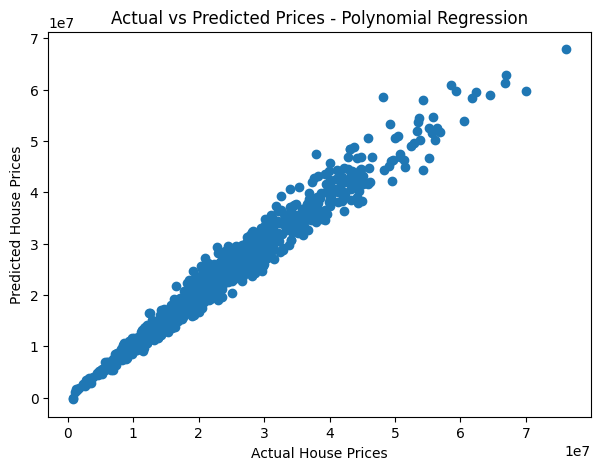

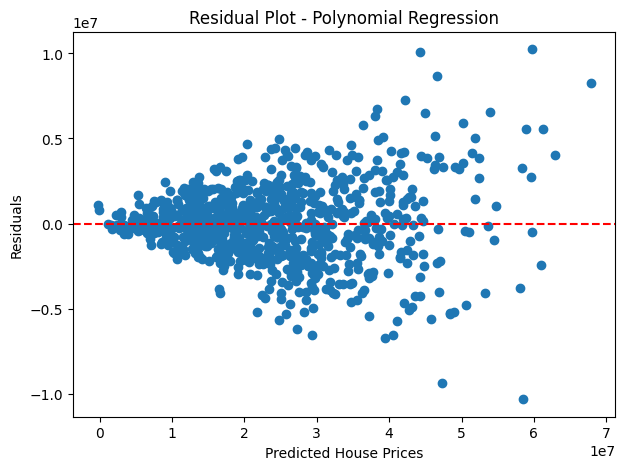

Mean Residual: 13531.442362179758


In [64]:
# Actual vs Predicted House Prices
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_poly)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted Prices - Polynomial Regression")
plt.show()

# Residual Plot
residuals = y_test - y_pred_poly

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_poly, residuals)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot - Polynomial Regression")
plt.show()

print("Mean Residual:", residuals.mean())

### H1. Training vs Testing Performance

In this section, we compare the model's performance on training and testing data. This helps us identify possible overfitting or underfitting and understand how well the model generalizes to unseen data.

In [65]:

# H1: Training vs Testing Performance

# Predictions on training data
y_pred_poly_train = poly_model.predict(X_train_poly)

# Training performance
r2_train_poly = r2_score(y_train, y_pred_poly_train)
rmse_train_poly = np.sqrt(mean_squared_error(y_train, y_pred_poly_train))
mae_train_poly = mean_absolute_error(y_train, y_pred_poly_train)

# Testing performance
r2_test_poly = r2_score(y_test, y_pred_poly)
rmse_test_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
mae_test_poly = mean_absolute_error(y_test, y_pred_poly)

# Display results
print("Polynomial Regression: Training vs Testing")
print("------------------------------------------")
print("Training R2 Score:", round(r2_train_poly, 4))
print("Testing R2 Score:", round(r2_test_poly, 4))
print("Training MAE:", round(mae_train_poly, 2))
print("Testing MAE:", round(mae_test_poly, 2))
print("Training RMSE:", round(rmse_train_poly, 2))
print("Testing RMSE:", round(rmse_test_poly, 2))

print("R2 Score Difference:",
      round(r2_train_poly - r2_test_poly, 4))


Polynomial Regression: Training vs Testing
------------------------------------------
Training R2 Score: 0.9685
Testing R2 Score: 0.9664
Training MAE: 1573241.65
Testing MAE: 1656922.8
Training RMSE: 2200985.09
Testing RMSE: 2267044.53
R2 Score Difference: 0.002


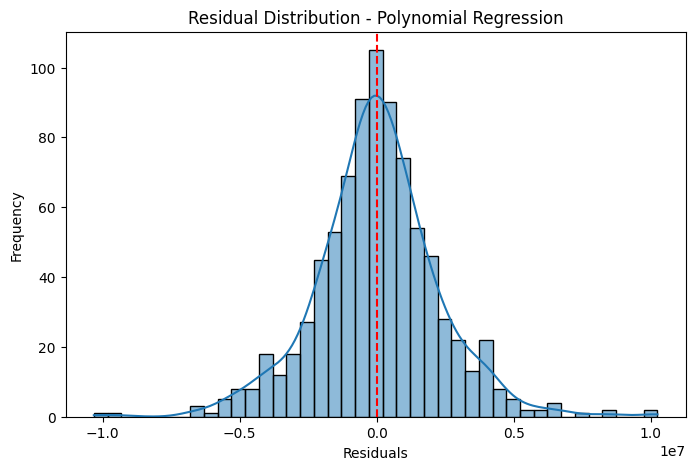

Mean Residual: 13531.44


In [66]:
residuals_poly = y_test - y_pred_poly

plt.figure(figsize=(8, 5))
sns.histplot(residuals_poly, kde=True)
plt.axvline(x=0, color="red", linestyle="--")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Polynomial Regression")
plt.show()

print("Mean Residual:", round(residuals_poly.mean(), 2))


## Part I: Final Analysis & Reporting

In this project, Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, and Gradient Descent methods were used to predict house prices.

Polynomial Regression achieved the highest R² score of approximately 0.9664 in the current test evaluation. Multiple Linear Regression and Gradient Descent achieved R² scores of approximately 0.9178, while Simple Linear Regression achieved approximately 0.5679.

These results suggest that Polynomial Regression performed best on the current test split. However, further validation is needed to confirm that it generalizes well to unseen data.